# Paso 4: Evaluación Comparativa Global, Análisis Gini vs. Entropía y Mapa Final Multiescala

**Curso:** Estructuras de Datos Avanzadas (EDA) — Unidad 2  
**Área de Estudio:** Distrito de Puno, Perú  

Este cuaderno cierra el flujo del proyecto integrando los resultados de los **Pasos 1, 2 y 3** en un análisis comparativo listo para el informe y la exposición final:
1. **Tabla comparativa global** de los 4 modelos obligatorios (`DecisionTree`, `Random Forest`, `XGBoost`, `LightGBM`) en las escalas **Micro (Edificaciones)** y **Macro (Zonificación 250m × 250m)**, junto al **trade-off precisión vs. velocidad**.
2. **Estudio comparativo Gini vs. Entropía** (curvas *Train vs. CV-5*, brecha de sobreajuste, profundidad óptima y número de hojas).
3. **Evaluación detallada en Test**: métricas **Macro y Weighted**, **acuerdo entre modelos (Cohen's Kappa $\kappa$)** y conteo de **aciertos unánimes vs. discrepancias**.
4. **Coherencia territorial multiescala (Micro ↔ Macro):** cruce espacial de las `652` edificaciones clasificadas sobre las `2,100` celdas de zonificación.
5. **Lámina cartográfica final clasificada (`300 DPI`)** y **Mapa Interactivo Integrado en Folium** con capas conmutables de zonificación, edificaciones y análisis espacial de **aciertos y discrepancias**.

## 1. Carga de Resultados, Datasets y Capas Geoespaciales

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
import seaborn as sns
import folium
from folium.plugins import Fullscreen, MiniMap

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, cohen_kappa_score
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'grid.alpha': 0.35
})

DIR_DATA_PUNO = Path("../data_puno")
DIR_FIGURES = Path("../figures")
DIR_FIGURES.mkdir(parents=True, exist_ok=True)
CRS_METRICO = "EPSG:32719"

# Resultados guardados en los Pasos 2 y 3
res_micro = pd.read_csv(DIR_DATA_PUNO / "resultados_micro_modelos.csv")
res_macro = pd.read_csv(DIR_DATA_PUNO / "resultados_macro_modelos.csv")

# Datasets tabulares completos (Micro y Macro)
df_micro = pd.read_csv(DIR_DATA_PUNO / "dataset_micro_edificaciones.csv")
df_macro = pd.read_csv(DIR_DATA_PUNO / "dataset_macro_zonificacion.csv")

# Capas geoespaciales finales (EPSG:4326)
gdf_boundary = gpd.read_file(DIR_DATA_PUNO / "puno_distrito_boundary.geojson")
gdf_buildings = gpd.read_file(DIR_DATA_PUNO / "puno_buildings_clasificados.geojson")
gdf_zonas = gpd.read_file(DIR_DATA_PUNO / "puno_zonificacion_macro.geojson")
gdf_water = gpd.read_file(DIR_DATA_PUNO / "puno_water_a.geojson")

FEATURES_MICRO = [
    'area_m2', 'perimetro_m', 'compacidad', 'relacion_aspecto', 'num_vertices',
    'dist_plaza_armas_m', 'dist_via_cercana_m', 'jerarquia_via',
    'densidad_edificios_150m', 'dist_vecino_cercano_m', 'pois_entorno_300m'
]
FEATURES_MACRO = [
    'num_edificios', 'pct_area_construida',
    'edificios_residenciales', 'edificios_comerciales', 'edificios_institucionales',
    'longitud_vias_m', 'num_tramos_via', 'pct_vias_arteriales', 'pct_vias_rurales_peat', 'dist_via_principal_m',
    'num_pois_celda', 'num_pois_500m', 'dist_poi_cercano_m', 'dist_transporte_m',
    'dist_plaza_armas_m', 'dist_lago_agua_m', 'dist_quebrada_rio_m'
]

print(f"Nivel Micro -> Total: {len(df_micro)} edificios | Etiquetados: {df_micro['clase_uso'].notna().sum()} | Features: {len(FEATURES_MICRO)}")
print(f"Nivel Macro -> Total: {len(df_macro)} celdas    | Etiquetadas: {df_macro['zona_macro'].notna().sum()} | Features: {len(FEATURES_MACRO)}")

Nivel Micro -> Total: 652 edificios | Etiquetados: 184 | Features: 11
Nivel Macro -> Total: 2100 celdas    | Etiquetadas: 1009 | Features: 17


## 2. Tabla Comparativa Global de Métricas: Nivel Micro vs. Nivel Macro

Consolidamos las 5 configuraciones evaluadas en los Pasos 2 y 3 (resaltando los mejores valores por métrica) y visualizamos el equilibrio entre **generalización (`CV-5 F1 Macro`)**, **desempeño en Test** y **velocidad computacional (`ms`)**.

In [2]:
orden_modelos = [
    'DecisionTree (Gini)',
    'DecisionTree (Entropía)',
    'Random Forest',
    'XGBoost',
    'LightGBM'
]
paradigmas = {
    'DecisionTree (Gini)': 'Árbol Simple (Gini)',
    'DecisionTree (Entropía)': 'Árbol Simple (Entropía)',
    'Random Forest': 'Ensamble Bagging',
    'XGBoost': 'Gradient Boosting',
    'LightGBM': 'Leaf-wise Boosting'
}

t_micro = res_micro.copy()
t_micro.insert(0, 'Escala', 'Nivel Micro (Edificaciones)')
t_macro = res_macro.copy()
t_macro.insert(0, 'Escala', 'Nivel Macro (Zonificación)')

df_global = pd.concat([t_micro, t_macro], ignore_index=True)
df_global['Paradigma'] = df_global['Modelo'].map(paradigmas)

cols_vista = [
    'Escala', 'Modelo', 'Paradigma',
    'Test Accuracy', 'Test Precision (Macro)', 'Test Recall (Macro)',
    'Test F1 (Macro)', 'CV-5 Accuracy', 'CV-5 F1 (Macro)', 'Tiempo Train (ms)'
]
df_global = df_global[cols_vista]
df_global.to_csv(DIR_DATA_PUNO / "comparativa_global_modelos.csv", index=False)

print("Tabla consolidada guardada en: data_puno/comparativa_global_modelos.csv")
metric_cols = ['Test Accuracy', 'Test Precision (Macro)', 'Test Recall (Macro)',
               'Test F1 (Macro)', 'CV-5 Accuracy', 'CV-5 F1 (Macro)']
display(
    df_global.style
    .format({c: "{:.4f}" for c in metric_cols} | {'Tiempo Train (ms)': "{:.2f}"})
    .background_gradient(subset=['CV-5 F1 (Macro)', 'Test F1 (Macro)'], cmap='YlGn')
    .set_caption("Comparativa Global de los 4 Modelos Obligatorios (Nivel Micro y Nivel Macro)")
)

pivot_f1 = df_global.pivot(
    index='Modelo',
    columns='Escala',
    values=['CV-5 F1 (Macro)', 'Test F1 (Macro)', 'Tiempo Train (ms)']
).loc[orden_modelos]
print("\nResumen lado a lado por Modelo (Micro vs. Macro):")
display(pivot_f1.round(4))

Tabla consolidada guardada en: data_puno/comparativa_global_modelos.csv


,Escala,Modelo,Paradigma,Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro),CV-5 Accuracy,CV-5 F1 (Macro),Tiempo Train (ms)
0,Nivel Micro (Edificaciones),XGBoost,Gradient Boosting,0.7826,0.7665,0.7675,0.7593,0.7540,0.7275,211.17
1,Nivel Micro (Edificaciones),Random Forest,Ensamble Bagging,0.8261,0.8343,0.8188,0.8046,0.7540,0.7264,406.26
2,Nivel Micro (Edificaciones),DecisionTree (Gini),Árbol Simple (Gini),0.7826,0.8295,0.7744,0.7498,0.7386,0.7115,2.22
3,Nivel Micro (Edificaciones),DecisionTree (Entropía),Árbol Simple (Entropía),0.7826,0.8295,0.7744,0.7498,0.7315,0.7013,1.66
4,Nivel Micro (Edificaciones),LightGBM,Leaf-wise Boosting,0.8261,0.8119,0.8085,0.8087,0.7251,0.6882,40.16
5,Nivel Macro (Zonificación),XGBoost,Gradient Boosting,0.7787,0.7095,0.7286,0.7133,0.7778,0.7029,707.93
6,Nivel Macro (Zonificación),LightGBM,Leaf-wise Boosting,0.7787,0.6966,0.7123,0.7040,0.7778,0.6991,308.63
7,Nivel Macro (Zonificación),Random Forest,Ensamble Bagging,0.7549,0.6782,0.7049,0.6854,0.7685,0.6969,730.84
8,Nivel Macro (Zonificación),DecisionTree (Gini),Árbol Simple (Gini),0.6838,0.6217,0.6293,0.6161,0.7169,0.6655,5.07
9,Nivel Macro (Zonificación),DecisionTree (Entropía),Árbol Simple (Entropía),0.6640,0.6195,0.6642,0.6179,0.7037,0.6393,8.13



Resumen lado a lado por Modelo (Micro vs. Macro):


CV-5 F1 (Macro)  \
Escala                  Nivel Macro (Zonificación)   
Modelo                                               
DecisionTree (Gini)                         0.6655   
DecisionTree (Entropía)                     0.6393   
Random Forest                               0.6969   
XGBoost                                     0.7029   
LightGBM                                    0.6991   

                                                     \
Escala                  Nivel Micro (Edificaciones)   
Modelo                                                
DecisionTree (Gini)                          0.7115   
DecisionTree (Entropía)                      0.7013   
Random Forest                                0.7264   
XGBoost                                      0.7275   
LightGBM                                     0.6882   

                                   Test F1 (Macro)  \
Escala                  Nivel Macro (Zonificación)   
Modelo                                               
DecisionTree (Gini)                         0.6161   
DecisionTree (Entropía)                     0.6179   
Random Forest                               0.6854   
XGBoost                                     0.7133   
LightGBM                                    0.7040   

                                                     \
Escala                  Nivel Micro (Edificaciones)   
Modelo                                                
DecisionTree (Gini)                          0.7498   
DecisionTree (Entropía)                      0.7498   
Random Forest                                0.8046   
XGBoost                                      0.7593   
LightGBM                                     0.8087   

                                 Tiempo Train (ms)                              
Escala                  Nivel Macro (Zonificación) Nivel Micro (Edificaciones)  
Modelo                                                                          
DecisionTree (Gini)                         5.0681                      2.2216  
DecisionTree (Entropía)                     8.1316                      1.6600  
Random Forest                             730.8374                    406.2603  
XGBoost                                   707.9304                    211.1694  
LightGBM                                  308.6277                     40.1641

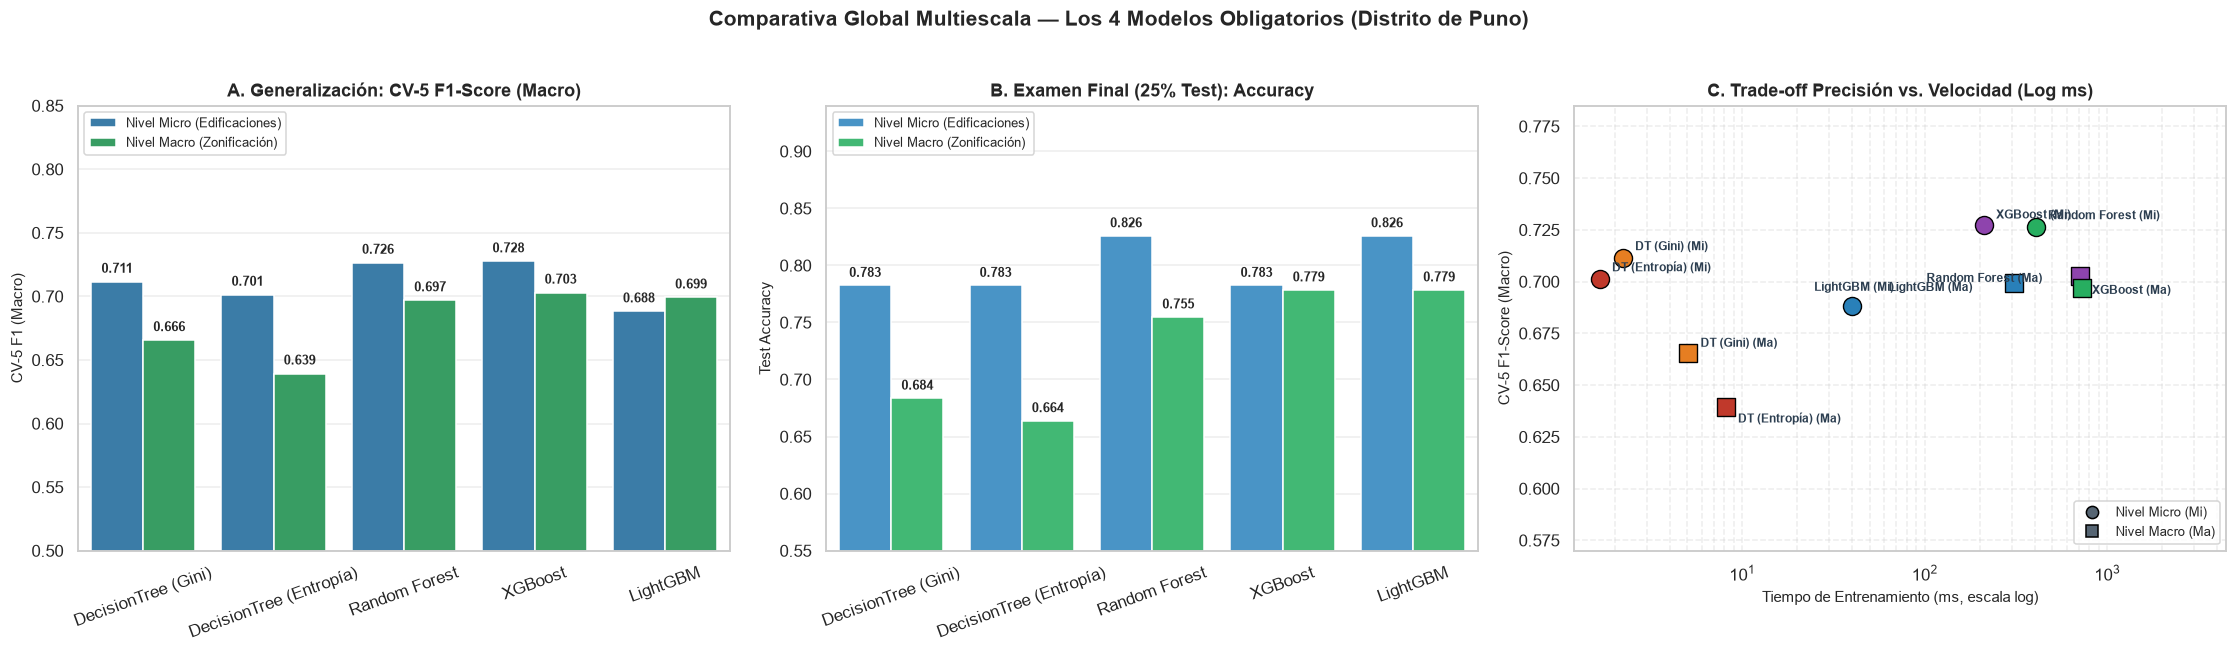

Figura guardada en: figures/04_comparativa_global_modelos.png


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(20.5, 5.8))

# 1. CV-5 F1-Score (Macro): Micro vs Macro
sns.barplot(
    data=df_global, x='Modelo', y='CV-5 F1 (Macro)', hue='Escala',
    order=orden_modelos, palette=['#2980b9', '#27ae60'], edgecolor='white', ax=axes[0]
)
axes[0].set_title("A. Generalización: CV-5 F1-Score (Macro)", fontsize=11.5, fontweight='bold')
axes[0].set_ylim(0.50, 0.85)
axes[0].tick_params(axis='x', rotation=20)
axes[0].set_xlabel("")
axes[0].legend(title="", loc='upper left', fontsize=8.5)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f"{h:.3f}", (p.get_x() + p.get_width()/2., h + 0.005),
                         ha='center', va='bottom', fontsize=8.2, fontweight='bold')

# 2. Test Accuracy: Micro vs Macro
sns.barplot(
    data=df_global, x='Modelo', y='Test Accuracy', hue='Escala',
    order=orden_modelos, palette=['#3498db', '#2ecc71'], edgecolor='white', ax=axes[1]
)
axes[1].set_title("B. Examen Final (25% Test): Accuracy", fontsize=11.5, fontweight='bold')
axes[1].set_ylim(0.55, 0.94)
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_xlabel("")
axes[1].legend(title="", loc='upper left', fontsize=8.5)
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f"{h:.3f}", (p.get_x() + p.get_width()/2., h + 0.005),
                         ha='center', va='bottom', fontsize=8.2, fontweight='bold')

# 3. Trade-off Precisión (CV-5 F1) vs Velocidad (escala logarítmica)
marcadores = {'Nivel Micro (Edificaciones)': 'o', 'Nivel Macro (Zonificación)': 's'}
colores_mod = {
    'DecisionTree (Gini)': '#e67e22',
    'DecisionTree (Entropía)': '#c0392b',
    'Random Forest': '#27ae60',
    'XGBoost': '#8e44ad',
    'LightGBM': '#2980b9'
}
offsets = {
    ('DecisionTree (Gini)', 'Mi'): (8, 5),
    ('DecisionTree (Entropía)', 'Mi'): (8, 5),
    ('DecisionTree (Gini)', 'Ma'): (8, 4),
    ('DecisionTree (Entropía)', 'Ma'): (8, -10),
    ('LightGBM', 'Mi'): (-25, 10),
    ('LightGBM', 'Ma'): (-82, -5),
    ('Random Forest', 'Mi'): (8, 5),
    ('Random Forest', 'Ma'): (-102, 4),
    ('XGBoost', 'Mi'): (8, 4),
    ('XGBoost', 'Ma'): (8, -12)
}

for _, row in df_global.iterrows():
    esc_tag = 'Mi' if 'Micro' in row['Escala'] else 'Ma'
    axes[2].scatter(
        row['Tiempo Train (ms)'], row['CV-5 F1 (Macro)'],
        s=140, color=colores_mod[row['Modelo']],
        marker=marcadores[row['Escala']], edgecolors='black', linewidth=0.9, zorder=3
    )
    etiqueta = f"{row['Modelo'].replace('DecisionTree ', 'DT ')} ({esc_tag})"
    dx, dy = offsets.get((row['Modelo'], esc_tag), (6, 4))
    axes[2].annotate(
        etiqueta, (row['Tiempo Train (ms)'], row['CV-5 F1 (Macro)']),
        textcoords="offset points", xytext=(dx, dy), fontsize=8.0, fontweight='bold', color='#2c3e50'
    )

axes[2].set_xscale('log')
axes[2].set_xlim(1.2, 4500)
axes[2].set_ylim(0.57, 0.785)
axes[2].set_title("C. Trade-off Precisión vs. Velocidad (Log ms)", fontsize=11.5, fontweight='bold')
axes[2].set_xlabel("Tiempo de Entrenamiento (ms, escala log)")
axes[2].set_ylabel("CV-5 F1-Score (Macro)")
axes[2].grid(True, which="both", ls="--", alpha=0.35)

legend_elems = [
    Line2D([0], [0], marker='o', color='w', label='Nivel Micro (Mi)', markerfacecolor='#566573', markeredgecolor='black', markersize=8),
    Line2D([0], [0], marker='s', color='w', label='Nivel Macro (Ma)', markerfacecolor='#566573', markeredgecolor='black', markersize=8),
]
axes[2].legend(handles=legend_elems, loc='lower right', fontsize=8.5, frameon=True, facecolor='white')

plt.suptitle("Comparativa Global Multiescala — Los 4 Modelos Obligatorios (Distrito de Puno)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "04_comparativa_global_modelos.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/04_comparativa_global_modelos.png")

## 3. Análisis Profundo: Gini vs. Entropía (*Information Gain*) y Control de Profundidad (`max_depth`)

Contrastamos directamente los dos criterios de impureza del árbol simple (`DecisionTreeClassifier`):
* **Impureza de Gini:** $G(t) = 1 - \sum_{k} p_k^2$ (cálculo cuadrático más rápido).
* **Entropía (*Information Gain*):** $H(t) = -\sum_{k} p_k \log_2(p_k)$ (usa logaritmos).

Al graficar **Train F1** frente a **CV-5 F1** desde `max_depth = 2` hasta `12`, se observa con claridad el fenómeno del **sobreajuste (*overfitting*)**: el puntaje en Train sigue subiendo mientras la validación cruzada se estanca o cae a partir de la profundidad óptima (`depth = 2` en Micro y `depth = 6` en Gini / `depth = 8` en Entropía en Macro).

,Escala,Criterio,max_depth óptimo,Profundidad real,N° Hojas,Train F1 (en óptimo),CV-5 F1 (en óptimo),Brecha Overfitting,Test F1 (Macro),Tiempo (ms)
0,Nivel Micro,Gini,2,2,4,0.7754,0.7115,0.0639,0.7498,1.6107
1,Nivel Micro,Entropía,2,2,4,0.7749,0.7013,0.0736,0.7498,3.4531
2,Nivel Macro,Gini,6,6,25,0.7405,0.6655,0.0750,0.6161,5.9540
3,Nivel Macro,Entropía,8,8,51,0.8000,0.6393,0.1607,0.6179,8.6904


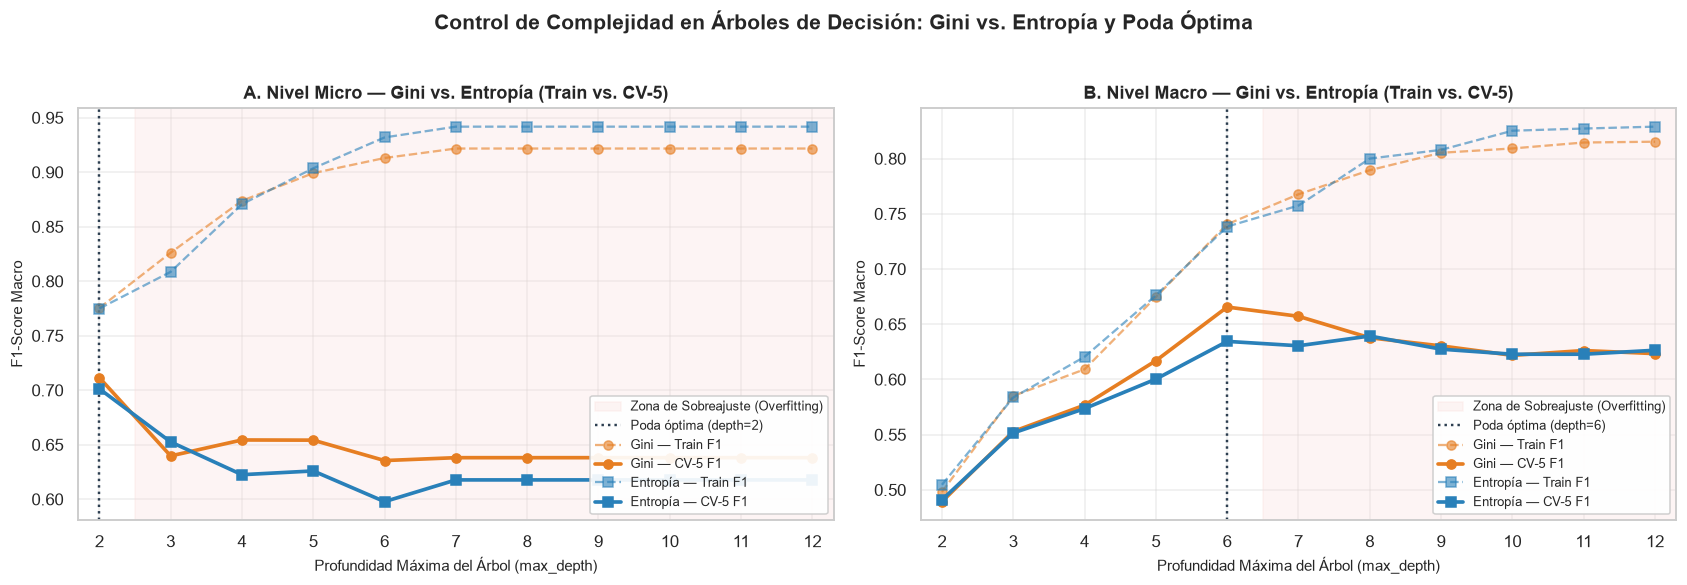

Figura guardada en: figures/04_gini_vs_entropia_curvas.png


In [4]:
# Preparar conjuntos etiquetados idénticos a los Pasos 2 y 3
df_mi_lab = df_micro.dropna(subset=['clase_uso']).copy().reset_index(drop=True)
X_mi = df_mi_lab[FEATURES_MICRO].copy()
le_mi = LabelEncoder()
y_mi = le_mi.fit_transform(df_mi_lab['clase_uso'])
X_mi_tr, X_mi_te, y_mi_tr, y_mi_te = train_test_split(X_mi, y_mi, test_size=0.25, random_state=42, stratify=y_mi)

df_ma_lab = df_macro.dropna(subset=['zona_macro']).copy().reset_index(drop=True)
X_ma = df_ma_lab[FEATURES_MACRO].copy()
le_ma = LabelEncoder()
y_ma = le_ma.fit_transform(df_ma_lab['zona_macro'])
X_ma_tr, X_ma_te, y_ma_tr, y_ma_te = train_test_split(X_ma, y_ma, test_size=0.25, random_state=42, stratify=y_ma)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
depths = list(range(2, 13))

def evaluar_gini_vs_entropia(X_tr, y_tr, X_te, y_te, min_leaf, class_weight=None):
    hist = {c: {'train': [], 'cv': []} for c in ['gini', 'entropy']}
    resumen = []
    for crit in ['gini', 'entropy']:
        for d in depths:
            tr_f1s, val_f1s = [], []
            for i_tr, i_val in cv.split(X_tr, y_tr):
                clf = DecisionTreeClassifier(
                    criterion=crit, max_depth=d, min_samples_leaf=min_leaf,
                    class_weight=class_weight, random_state=42
                )
                clf.fit(X_tr.iloc[i_tr], y_tr[i_tr])
                tr_f1s.append(f1_score(y_tr[i_tr], clf.predict(X_tr.iloc[i_tr]), average='macro'))
                val_f1s.append(f1_score(y_tr[i_val], clf.predict(X_tr.iloc[i_val]), average='macro'))
            hist[crit]['train'].append(np.mean(tr_f1s))
            hist[crit]['cv'].append(np.mean(val_f1s))

        best_idx = int(np.argmax(hist[crit]['cv']))
        best_d = depths[best_idx]
        t0 = time.perf_counter()
        best_clf = DecisionTreeClassifier(
            criterion=crit, max_depth=best_d, min_samples_leaf=min_leaf,
            class_weight=class_weight, random_state=42
        )
        best_clf.fit(X_tr, y_tr)
        t_ms = (time.perf_counter() - t0) * 1000
        y_p = best_clf.predict(X_te)
        resumen.append({
            'Criterio': 'Gini' if crit == 'gini' else 'Entropía',
            'max_depth óptimo': best_d,
            'Profundidad real': best_clf.get_depth(),
            'N° Hojas': best_clf.get_n_leaves(),
            'Train F1 (en óptimo)': hist[crit]['train'][best_idx],
            'CV-5 F1 (en óptimo)': hist[crit]['cv'][best_idx],
            'Brecha Overfitting': hist[crit]['train'][best_idx] - hist[crit]['cv'][best_idx],
            'Test F1 (Macro)': f1_score(y_te, y_p, average='macro'),
            'Tiempo (ms)': t_ms
        })
    return hist, pd.DataFrame(resumen)

hist_mi, tabla_ge_mi = evaluar_gini_vs_entropia(X_mi_tr, y_mi_tr, X_mi_te, y_mi_te, min_leaf=3, class_weight=None)
hist_ma, tabla_ge_ma = evaluar_gini_vs_entropia(X_ma_tr, y_ma_tr, X_ma_te, y_ma_te, min_leaf=5, class_weight='balanced')

tabla_ge_mi.insert(0, 'Escala', 'Nivel Micro')
tabla_ge_ma.insert(0, 'Escala', 'Nivel Macro')
tabla_ge = pd.concat([tabla_ge_mi, tabla_ge_ma], ignore_index=True)
display(tabla_ge.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
for ax, hist, opt_d, titulo in [
    (axes[0], hist_mi, int(tabla_ge_mi.loc[tabla_ge_mi['Criterio'] == 'Gini', 'max_depth óptimo'].iloc[0]), "A. Nivel Micro — Gini vs. Entropía (Train vs. CV-5)"),
    (axes[1], hist_ma, int(tabla_ge_ma.loc[tabla_ge_ma['Criterio'] == 'Gini', 'max_depth óptimo'].iloc[0]), "B. Nivel Macro — Gini vs. Entropía (Train vs. CV-5)")
]:
    ax.axvspan(opt_d + 0.5, 12.3, color='#fadbd8', alpha=0.28, label='Zona de Sobreajuste (Overfitting)')
    ax.axvline(opt_d, color='#2c3e50', linestyle=':', linewidth=1.6, label=f'Poda óptima (depth={opt_d})')
    ax.plot(depths, hist['gini']['train'], 'o--', color='#e67e22', alpha=0.6, label='Gini — Train F1')
    ax.plot(depths, hist['gini']['cv'], 'o-', color='#e67e22', linewidth=2.4, label='Gini — CV-5 F1')
    ax.plot(depths, hist['entropy']['train'], 's--', color='#2980b9', alpha=0.6, label='Entropía — Train F1')
    ax.plot(depths, hist['entropy']['cv'], 's-', color='#2980b9', linewidth=2.4, label='Entropía — CV-5 F1')
    ax.set_title(titulo, fontsize=11.5, fontweight='bold')
    ax.set_xlabel("Profundidad Máxima del Árbol (max_depth)")
    ax.set_ylabel("F1-Score Macro")
    ax.set_xticks(depths)
    ax.set_xlim(1.7, 12.3)
    ax.legend(fontsize=8.2, loc='lower right', frameon=True, facecolor='white', framealpha=0.92)
    ax.grid(True, alpha=0.35)

plt.suptitle("Control de Complejidad en Árboles de Decisión: Gini vs. Entropía y Poda Óptima",
             fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "04_gini_vs_entropia_curvas.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/04_gini_vs_entropia_curvas.png")

## 4. Evaluación Detallada en Test: Métricas Macro/Weighted, Acuerdo entre Modelos y Discrepancias

Evaluamos las 5 configuraciones en los conjuntos exactos de prueba (Micro: `46` edificios; Macro: `253` celdas) para:
1. Reportar tanto **Precision/F1 Macro** (trata todas las clases por igual) como **Weighted** (ponderado por frecuencia).
2. Medir la **concordancia entre los 4 paradigmas** mediante el índice **Cohen's Kappa ($\kappa$)** *(donde $\kappa > 0.80$ indica acuerdo casi perfecto y $0.60\text{–}0.80$ acuerdo sustancial)*.
3. Clasificar cada registro de Test en **Acierto Unánime (4/4)**, **Discrepancia entre Modelos** o **Error Unánime (0/4)** para mapearlos visualmente.

Métricas completas en Test (Macro y Weighted):


,Escala,Modelo,Accuracy,Balanced Acc,Prec (Macro),Prec (Weighted),Recall (Macro),F1 (Macro),F1 (Weighted)
0,Micro,DecisionTree (Gini),0.7826,0.7744,0.8295,0.8318,0.7744,0.7498,0.7560
1,Micro,DecisionTree (Entropía),0.7826,0.7744,0.8295,0.8318,0.7744,0.7498,0.7560
2,Micro,Random Forest,0.8261,0.8188,0.8343,0.8490,0.8188,0.8046,0.8169
3,Micro,XGBoost,0.7826,0.7675,0.7665,0.7845,0.7675,0.7593,0.7763
4,Micro,LightGBM,0.8261,0.8085,0.8119,0.8203,0.8085,0.8087,0.8216
5,Macro,DecisionTree (Gini),0.6838,0.6293,0.6217,0.7592,0.6293,0.6161,0.7123
6,Macro,DecisionTree (Entropía),0.6640,0.6642,0.6195,0.7742,0.6642,0.6179,0.6929
7,Macro,Random Forest,0.7549,0.7049,0.6782,0.7961,0.7049,0.6854,0.7702
8,Macro,XGBoost,0.7787,0.7286,0.7095,0.7987,0.7286,0.7133,0.7850
9,Macro,LightGBM,0.7787,0.7123,0.6966,0.7845,0.7123,0.7040,0.7812


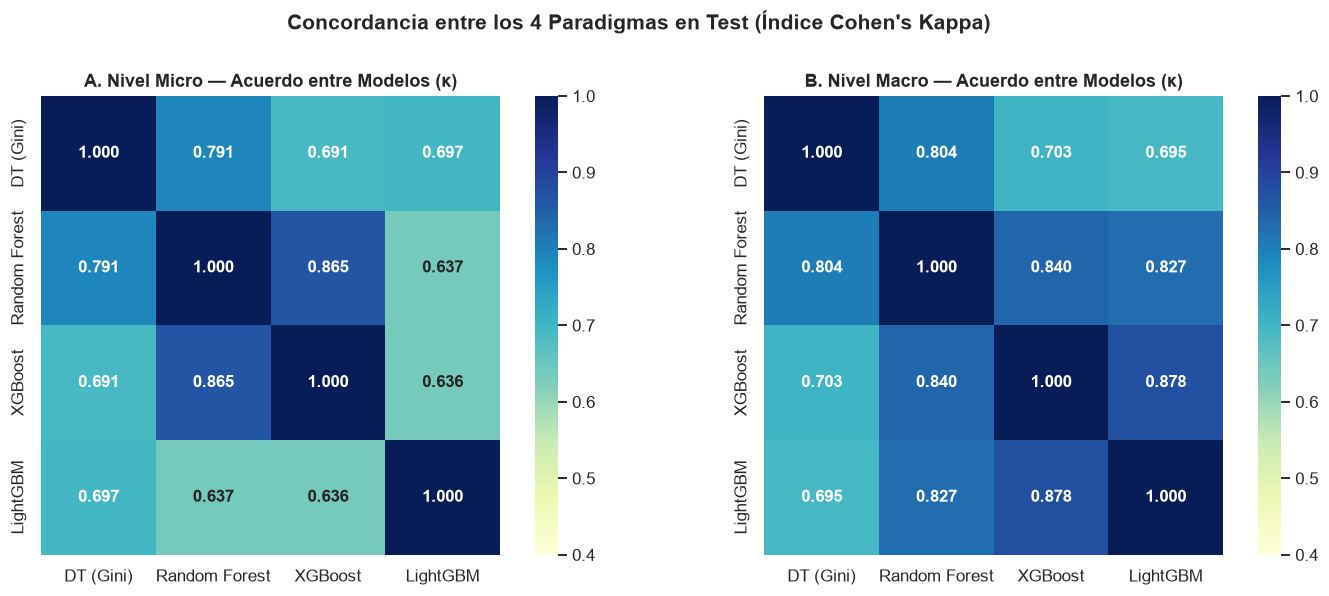

Figura guardada en: figures/04_acuerdo_modelos_kappa.png


In [5]:
mejor_d_gini_mi = int(tabla_ge_mi.loc[tabla_ge_mi['Criterio'] == 'Gini', 'max_depth óptimo'].iloc[0])
mejor_d_ent_mi = int(tabla_ge_mi.loc[tabla_ge_mi['Criterio'] == 'Entropía', 'max_depth óptimo'].iloc[0])
mejor_d_gini_ma = int(tabla_ge_ma.loc[tabla_ge_ma['Criterio'] == 'Gini', 'max_depth óptimo'].iloc[0])
mejor_d_ent_ma = int(tabla_ge_ma.loc[tabla_ge_ma['Criterio'] == 'Entropía', 'max_depth óptimo'].iloc[0])

modelos_micro = {
    'DecisionTree (Gini)': DecisionTreeClassifier(criterion='gini', max_depth=mejor_d_gini_mi, min_samples_leaf=3, random_state=42),
    'DecisionTree (Entropía)': DecisionTreeClassifier(criterion='entropy', max_depth=mejor_d_ent_mi, min_samples_leaf=3, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=2, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42),
    'LightGBM': LGBMClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, num_leaves=15, min_child_samples=10, random_state=42, verbose=-1)
}

modelos_macro = {
    'DecisionTree (Gini)': DecisionTreeClassifier(criterion='gini', max_depth=mejor_d_gini_ma, min_samples_leaf=5, class_weight='balanced', random_state=42),
    'DecisionTree (Entropía)': DecisionTreeClassifier(criterion='entropy', max_depth=mejor_d_ent_ma, min_samples_leaf=5, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=250, max_depth=12, min_samples_leaf=3, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42),
    'LightGBM': LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.05, num_leaves=25, min_child_samples=15, class_weight='balanced', random_state=42, verbose=-1)
}

def evaluar_test_detallado(modelos_dict, X_tr, y_tr, X_te, y_te, escala, usar_sw_xgb=False):
    preds = {}
    filas = []
    for nombre, m in modelos_dict.items():
        if usar_sw_xgb and nombre == 'XGBoost':
            m.fit(X_tr, y_tr, sample_weight=compute_sample_weight('balanced', y_tr))
        else:
            m.fit(X_tr, y_tr)
        yp = m.predict(X_te)
        preds[nombre] = yp
        filas.append({
            'Escala': escala,
            'Modelo': nombre,
            'Accuracy': accuracy_score(y_te, yp),
            'Balanced Acc': balanced_accuracy_score(y_te, yp),
            'Prec (Macro)': precision_score(y_te, yp, average='macro', zero_division=0),
            'Prec (Weighted)': precision_score(y_te, yp, average='weighted', zero_division=0),
            'Recall (Macro)': recall_score(y_te, yp, average='macro', zero_division=0),
            'F1 (Macro)': f1_score(y_te, yp, average='macro', zero_division=0),
            'F1 (Weighted)': f1_score(y_te, yp, average='weighted', zero_division=0)
        })
    return preds, pd.DataFrame(filas)

preds_mi, det_mi = evaluar_test_detallado(modelos_micro, X_mi_tr, y_mi_tr, X_mi_te, y_mi_te, 'Micro', usar_sw_xgb=False)
preds_ma, det_ma = evaluar_test_detallado(modelos_macro, X_ma_tr, y_ma_tr, X_ma_te, y_ma_te, 'Macro', usar_sw_xgb=True)

df_detallado = pd.concat([det_mi, det_ma], ignore_index=True)
df_detallado.to_csv(DIR_DATA_PUNO / "comparativa_global_detallada.csv", index=False)
print("Métricas completas en Test (Macro y Weighted):")
display(df_detallado.round(4))

# Matrices de acuerdo entre las 4 familias de modelos (Cohen's Kappa)
familias = ['DecisionTree (Gini)', 'Random Forest', 'XGBoost', 'LightGBM']
nombres_cortos = ['DT (Gini)', 'Random Forest', 'XGBoost', 'LightGBM']

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for ax, preds, titulo in [
    (axes[0], preds_mi, "A. Nivel Micro — Acuerdo entre Modelos (κ)"),
    (axes[1], preds_ma, "B. Nivel Macro — Acuerdo entre Modelos (κ)")
]:
    mat = pd.DataFrame(index=nombres_cortos, columns=nombres_cortos, dtype=float)
    for f1, n1 in zip(familias, nombres_cortos):
        for f2, n2 in zip(familias, nombres_cortos):
            mat.loc[n1, n2] = cohen_kappa_score(preds[f1], preds[f2])
    sns.heatmap(mat, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.4, vmax=1.0,
                annot_kws={'size': 11, 'weight': 'bold'}, ax=ax, square=True)
    ax.set_title(titulo, fontsize=11.5, fontweight='bold')

plt.suptitle("Concordancia entre los 4 Paradigmas en Test (Índice Cohen's Kappa)",
             fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "04_acuerdo_modelos_kappa.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/04_acuerdo_modelos_kappa.png")

Resumen de Aciertos Unánimes vs. Discrepancias en Test:


,Micro (n=46),Micro (%),Macro (n=253),Macro (%)
estado_eval,,,,
Acierto Unánime (4/4),31,67.4,158,62.5
Discrepancia entre Modelos,12,26.1,56,22.1
Error Unánime (0/4),3,6.5,39,15.4


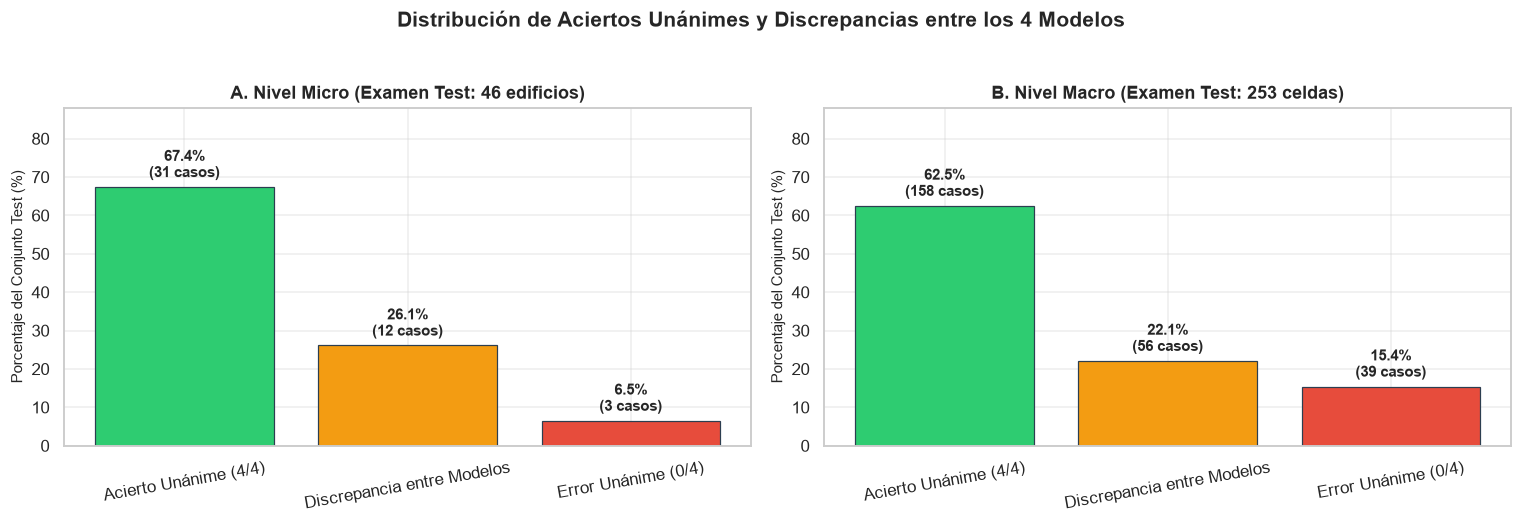

Figura guardada en: figures/04_aciertos_discrepancias_test.png

Ejemplos de Discrepancias en Test — Nivel Micro:


,osm_id,name,Real,DT,RF,XGB,LGBM,n_modelos_aciertan,estado_eval
183,1562641688,NaN,Comercial_Servicios,Comercial_Servicios,Institucional,Institucional,Comercial_Servicios,2,Discrepancia entre Modelos
79,771083551,NaN,Comercial_Servicios,Residencial,Comercial_Servicios,Comercial_Servicios,Residencial,2,Discrepancia entre Modelos
157,1157101540,NaN,Institucional,Comercial_Servicios,Institucional,Institucional,Comercial_Servicios,2,Discrepancia entre Modelos
178,1545548133,Coliseo Salcedo,Institucional,Comercial_Servicios,Comercial_Servicios,Comercial_Servicios,Institucional,1,Discrepancia entre Modelos
88,844606622,NaN,Institucional,Residencial,Residencial,Residencial,Institucional,1,Discrepancia entre Modelos
11,376679241,Sonesta Hotel Posadas del Inca Puno,Comercial_Servicios,Comercial_Servicios,Comercial_Servicios,Institucional,Institucional,2,Discrepancia entre Modelos



Ejemplos de Discrepancias en Test — Nivel Macro:


,cell_id,Real,DT,RF,XGB,LGBM,n_modelos_aciertan,estado_eval
859,7312,Rural_Agricola_Natural,Areas_Verdes_Recreacion,Rural_Agricola_Natural,Rural_Agricola_Natural,Rural_Agricola_Natural,3,Discrepancia entre Modelos
736,6438,Urbano_Residencial,Urbano_Residencial,Urbano_Residencial,Areas_Verdes_Recreacion,Urbano_Residencial,3,Discrepancia entre Modelos
777,6621,Urbano_Residencial,Areas_Verdes_Recreacion,Urbano_Residencial,Urbano_Residencial,Urbano_Residencial,3,Discrepancia entre Modelos
723,6383,Equipamiento_Productivo,Areas_Verdes_Recreacion,Equipamiento_Productivo,Rural_Agricola_Natural,Equipamiento_Productivo,2,Discrepancia entre Modelos
993,7610,Rural_Agricola_Natural,Areas_Verdes_Recreacion,Rural_Agricola_Natural,Rural_Agricola_Natural,Rural_Agricola_Natural,3,Discrepancia entre Modelos
502,5651,Urbano_Residencial,Areas_Verdes_Recreacion,Areas_Verdes_Recreacion,Urbano_Residencial,Areas_Verdes_Recreacion,1,Discrepancia entre Modelos


In [6]:
def analizar_aciertos_discrepancias(df_lab, X_te, y_te, preds, le, id_col, extra_cols=None):
    out = df_lab.loc[X_te.index, [id_col] + (extra_cols or [])].copy()
    out['Real'] = le.inverse_transform(y_te)
    for col_short, mod_name in [('DT', 'DecisionTree (Gini)'), ('RF', 'Random Forest'), ('XGB', 'XGBoost'), ('LGBM', 'LightGBM')]:
        out[col_short] = le.inverse_transform(preds[mod_name])

    aciertos = (
        (out['DT'] == out['Real']).astype(int) +
        (out['RF'] == out['Real']).astype(int) +
        (out['XGB'] == out['Real']).astype(int) +
        (out['LGBM'] == out['Real']).astype(int)
    )
    out['n_modelos_aciertan'] = aciertos
    out['estado_eval'] = np.select(
        [aciertos == 4, aciertos == 0],
        ['Acierto Unánime (4/4)', 'Error Unánime (0/4)'],
        default='Discrepancia entre Modelos'
    )
    return out

eval_mi = analizar_aciertos_discrepancias(df_mi_lab, X_mi_te, y_mi_te, preds_mi, le_mi, 'osm_id', ['name'])
eval_ma = analizar_aciertos_discrepancias(df_ma_lab, X_ma_te, y_ma_te, preds_ma, le_ma, 'cell_id')

orden_estados = ['Acierto Unánime (4/4)', 'Discrepancia entre Modelos', 'Error Unánime (0/4)']
colores_estados = ['#2ecc71', '#f39c12', '#e74c3c']

resumen_est = pd.DataFrame({
    'Micro (n=46)': eval_mi['estado_eval'].value_counts().reindex(orden_estados, fill_value=0),
    'Micro (%)': (eval_mi['estado_eval'].value_counts(normalize=True).reindex(orden_estados, fill_value=0) * 100).round(1),
    'Macro (n=253)': eval_ma['estado_eval'].value_counts().reindex(orden_estados, fill_value=0),
    'Macro (%)': (eval_ma['estado_eval'].value_counts(normalize=True).reindex(orden_estados, fill_value=0) * 100).round(1)
})
print("Resumen de Aciertos Unánimes vs. Discrepancias en Test:")
display(resumen_est)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, col_n, col_pct, titulo in [
    (axes[0], 'Micro (n=46)', 'Micro (%)', "A. Nivel Micro (Examen Test: 46 edificios)"),
    (axes[1], 'Macro (n=253)', 'Macro (%)', "B. Nivel Macro (Examen Test: 253 celdas)")
]:
    bars = ax.bar(orden_estados, resumen_est[col_pct], color=colores_estados, edgecolor='#2c3e50', linewidth=0.8)
    ax.set_title(titulo, fontsize=11.5, fontweight='bold')
    ax.set_ylabel("Porcentaje del Conjunto Test (%)")
    ax.set_ylim(0, 88)
    ax.tick_params(axis='x', rotation=10)
    for b, cnt in zip(bars, resumen_est[col_n]):
        ax.annotate(f"{b.get_height():.1f}%\n({cnt} casos)",
                    (b.get_x() + b.get_width()/2., b.get_height() + 1.5),
                    ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.suptitle("Distribución de Aciertos Unánimes y Discrepancias entre los 4 Modelos",
             fontsize=13.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "04_aciertos_discrepancias_test.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/04_aciertos_discrepancias_test.png")

print("\nEjemplos de Discrepancias en Test — Nivel Micro:")
display(eval_mi[eval_mi['estado_eval'] == 'Discrepancia entre Modelos'].head(6))

print("\nEjemplos de Discrepancias en Test — Nivel Macro:")
display(eval_ma[eval_ma['estado_eval'] == 'Discrepancia entre Modelos'].head(6))

## 5. Análisis de Coherencia Territorial Multiescala (Nivel Micro ↔ Nivel Macro)

Comprobamos si las clasificaciones independientes a nivel de edificio (**Nivel Micro**) y a nivel de cuadrante de $250\text{ m} \times 250\text{ m}$ (**Nivel Macro**) guardan **coherencia espacial real** sobre el territorio de Puno.

Edificaciones cruzadas espacialmente con celdas Macro: 652 / 652


clase_final,Comercial_Servicios,Institucional,Residencial,All
zona_final,,,,
Areas_Verdes_Recreacion,29,64,43,136
Equipamiento_Productivo,119,186,140,445
Rural_Agricola_Natural,1,2,14,17
Urbano_Residencial,19,29,6,54
All,168,281,203,652


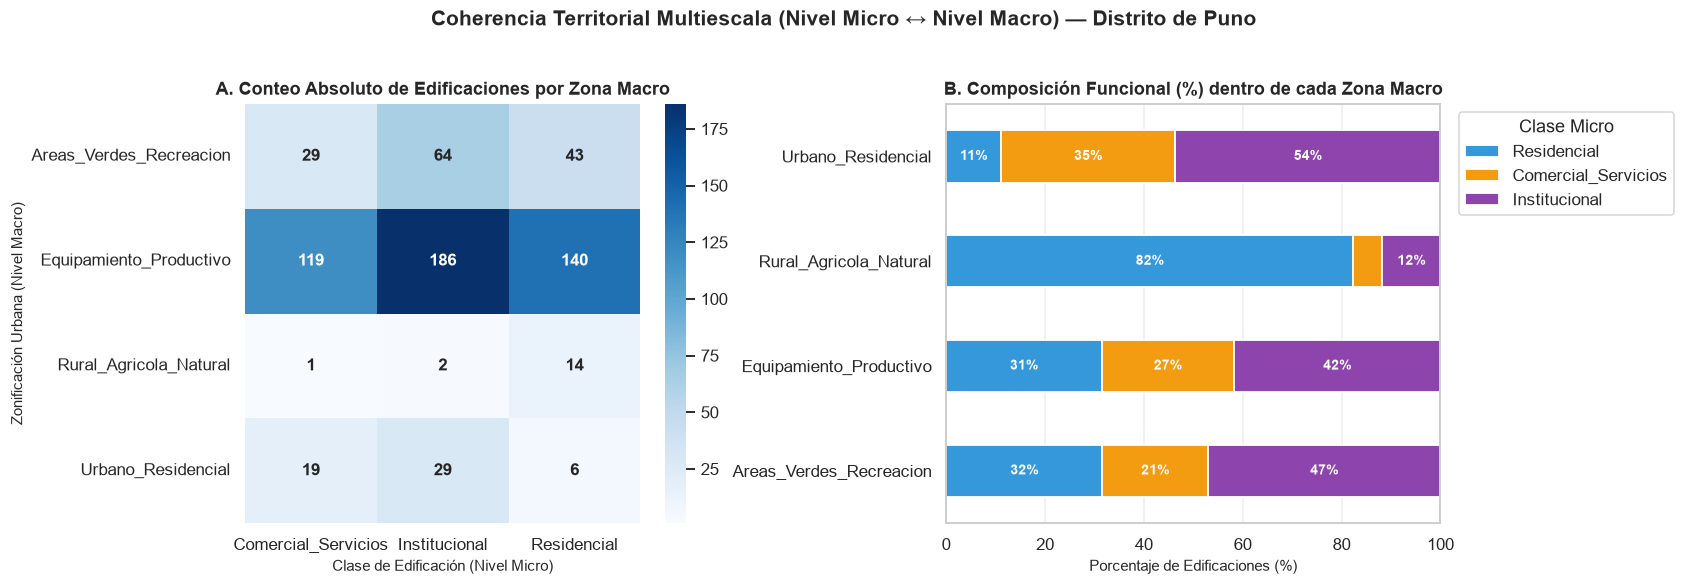

Figura guardada en: figures/04_coherencia_multiescala.png


In [7]:
b_utm = gdf_buildings.to_crs(CRS_METRICO).copy()
z_utm = gdf_zonas.to_crs(CRS_METRICO).copy()

b_cent = b_utm[['osm_id', 'name', 'clase_final', 'origen_etiqueta', 'area_m2', 'geometry']].copy()
b_cent['geometry'] = b_cent.geometry.centroid

cruce = gpd.sjoin(
    b_cent,
    z_utm[['cell_id', 'zona_final', 'geometry']],
    how='inner',
    predicate='within'
)

ct_abs = pd.crosstab(cruce['zona_final'], cruce['clase_final'], margins=True)
ct_pct = pd.crosstab(cruce['zona_final'], cruce['clase_final'], normalize='index') * 100

print(f"Edificaciones cruzadas espacialmente con celdas Macro: {len(cruce)} / {len(gdf_buildings)}")
display(ct_abs)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

sns.heatmap(
    ct_abs.drop(index='All', columns='All'),
    annot=True, fmt='d', cmap='Blues',
    annot_kws={'size': 11, 'weight': 'bold'}, ax=axes[0]
)
axes[0].set_title("A. Conteo Absoluto de Edificaciones por Zona Macro", fontsize=11.5, fontweight='bold')
axes[0].set_xlabel("Clase de Edificación (Nivel Micro)")
axes[0].set_ylabel("Zonificación Urbana (Nivel Macro)")

colores_micro_plot = ['#3498db', '#f39c12', '#8e44ad']
orden_cols_mi = ['Residencial', 'Comercial_Servicios', 'Institucional']
ct_pct[orden_cols_mi].plot(
    kind='barh', stacked=True, color=colores_micro_plot, ax=axes[1], edgecolor='white', linewidth=1.2
)
axes[1].set_title("B. Composición Funcional (%) dentro de cada Zona Macro", fontsize=11.5, fontweight='bold')
axes[1].set_xlabel("Porcentaje de Edificaciones (%)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)
axes[1].legend(title="Clase Micro", bbox_to_anchor=(1.02, 1), loc='upper left')

# Etiquetas de porcentaje dentro de las barras apiladas
for container in axes[1].containers:
    labels = [f"{v:.0f}%" if v >= 10 else "" for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center', color='white', fontsize=9, fontweight='bold')

plt.suptitle("Coherencia Territorial Multiescala (Nivel Micro ↔ Nivel Macro) — Distrito de Puno",
             fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "04_coherencia_multiescala.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/04_coherencia_multiescala.png")

## 6. Mapa Cartográfico Final Clasificado Multiescala (`300 DPI`) — Síntesis Visual para el Informe

A diferencia del mapa de datos crudos del **Paso 1**, esta lámina cartográfica muestra el **resultado final completo de nuestros modelos de Machine Learning**:
* **Panel A (Escala Distrital — Nivel Macro):** las **`2,100` celdas de $250\text{ m} \times 250\text{ m}$** zonificadas en todo el Distrito de Puno (verificadas + predichas con **XGBoost**).
* **Panel B (Zoom al Núcleo Urbano — Integración Micro + Macro):** la zonificación Macro como base territorial y sobre ella las **`652` edificaciones clasificadas** en el Nivel Micro (con **XGBoost**).

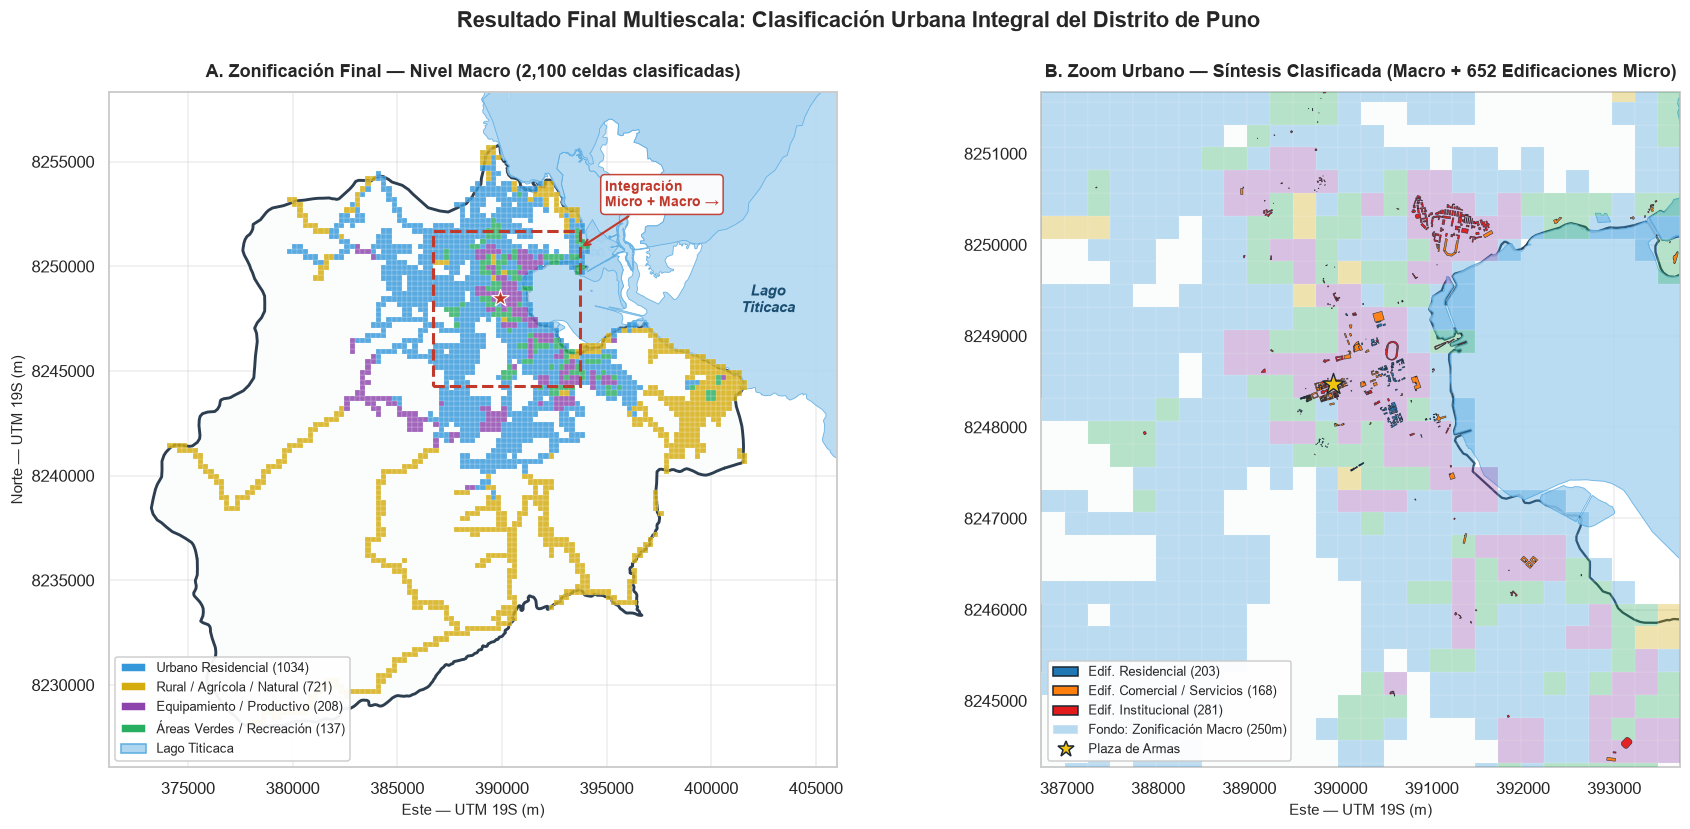

Figura guardada en: figures/04_mapa_final_multiescala.png


In [8]:
boundary_utm = gdf_boundary.to_crs(CRS_METRICO)
water_utm = gdf_water.to_crs(CRS_METRICO)
plaza_utm = gpd.GeoSeries([Point(-70.0280, -15.8402)], crs="EPSG:4326").to_crs(CRS_METRICO).iloc[0]

colores_macro = {
    'Urbano_Residencial': '#3498db',
    'Rural_Agricola_Natural': '#d4ac0d',
    'Equipamiento_Productivo': '#8e44ad',
    'Areas_Verdes_Recreacion': '#27ae60'
}
colores_micro = {
    'Residencial': '#1f77b4',
    'Comercial_Servicios': '#ff7f0e',
    'Institucional': '#e31a1c'
}

px, py = plaza_utm.x, plaza_utm.y
z_minx, z_maxx = px - 3200, px + 3800
z_miny, z_maxy = py - 4200, py + 3200

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 7.6), gridspec_kw={'width_ratios': [1.05, 1]})

# --- PANEL A: ZONIFICACIÓN MACRO COMPLETA EN EL DISTRITO DE PUNO ---
boundary_utm.plot(ax=ax1, color='#fbfcfc', edgecolor='#2c3e50', linewidth=1.9, zorder=1)
water_utm.plot(ax=ax1, color='#aed6f1', edgecolor='#5dade2', linewidth=0.6, alpha=0.85, zorder=2)

for zona, col in colores_macro.items():
    z_utm[z_utm['zona_final'] == zona].plot(ax=ax1, color=col, edgecolor='white', linewidth=0.15, alpha=0.82, zorder=3)

rect_z = Rectangle((z_minx, z_miny), z_maxx - z_minx, z_maxy - z_miny,
                   linewidth=2.0, edgecolor='#c0392b', facecolor='none', linestyle='--', zorder=5)
ax1.add_patch(rect_z)
ax1.scatter([px], [py], color='#c0392b', marker='*', s=140, edgecolor='white', linewidth=0.8, zorder=6)

bminx, bminy, bmaxx, bmaxy = boundary_utm.total_bounds
ax1.set_xlim(bminx - 2000, bmaxx + 4500)
ax1.set_ylim(bminy - 2000, bmaxy + 2500)
ax1.annotate("Integración\nMicro + Macro →", xy=(z_maxx, z_maxy - 800),
             xytext=(z_maxx + 1200, z_maxy + 1200),
             fontsize=9.2, fontweight='bold', color='#c0392b',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#c0392b', alpha=0.93),
             arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.4))
ax1.text(bmaxx + 1200, bmaxy - 8000, "Lago\nTiticaca", fontsize=10, style='italic',
         fontweight='bold', color='#1b4f72', ha='center', zorder=6)

ax1.set_title("A. Zonificación Final — Nivel Macro (2,100 celdas clasificadas)", pad=10)
ax1.set_xlabel("Este — UTM 19S (m)")
ax1.set_ylabel("Norte — UTM 19S (m)")
ax1.ticklabel_format(style='plain', axis='both')

cnt_ma_f = z_utm['zona_final'].value_counts()
handles_a = [
    mpatches.Patch(facecolor='#3498db', label=f"Urbano Residencial ({int(cnt_ma_f.get('Urbano_Residencial', 0))})"),
    mpatches.Patch(facecolor='#d4ac0d', label=f"Rural / Agrícola / Natural ({int(cnt_ma_f.get('Rural_Agricola_Natural', 0))})"),
    mpatches.Patch(facecolor='#8e44ad', label=f"Equipamiento / Productivo ({int(cnt_ma_f.get('Equipamiento_Productivo', 0))})"),
    mpatches.Patch(facecolor='#27ae60', label=f"Áreas Verdes / Recreación ({int(cnt_ma_f.get('Areas_Verdes_Recreacion', 0))})"),
    mpatches.Patch(facecolor='#aed6f1', edgecolor='#5dade2', label='Lago Titicaca')
]
ax1.legend(handles=handles_a, loc='lower left', fontsize=8.4, frameon=True, facecolor='white', framealpha=0.94)

# --- PANEL B: ZOOM AL NÚCLEO URBANO (ZONAS MACRO + EDIFICACIONES MICRO CLASIFICADAS) ---
boundary_utm.plot(ax=ax2, color='#fbfcfc', edgecolor='#2c3e50', linewidth=1.5, zorder=1)
water_utm.plot(ax=ax2, color='#aed6f1', edgecolor='#5dade2', linewidth=0.6, alpha=0.85, zorder=2)

for zona, col in colores_macro.items():
    z_utm[z_utm['zona_final'] == zona].plot(ax=ax2, color=col, edgecolor='white', linewidth=0.25, alpha=0.32, zorder=3)

for clase, col in colores_micro.items():
    b_utm[b_utm['clase_final'] == clase].plot(ax=ax2, color=col, edgecolor='#1c2833', linewidth=0.35, alpha=0.95, zorder=5)

ax2.scatter([px], [py], color='#f1c40f', marker='*', s=210, edgecolor='#1c2833', linewidth=0.9, zorder=7)
ax2.set_xlim(z_minx, z_maxx)
ax2.set_ylim(z_miny, z_maxy)
ax2.set_title("B. Zoom Urbano — Síntesis Clasificada (Macro + 652 Edificaciones Micro)", pad=10)
ax2.set_xlabel("Este — UTM 19S (m)")
ax2.set_ylabel("")
ax2.ticklabel_format(style='plain', axis='both')

cnt_mi_f = b_utm['clase_final'].value_counts()
handles_b = [
    mpatches.Patch(facecolor='#1f77b4', edgecolor='#1c2833', label=f"Edif. Residencial ({int(cnt_mi_f.get('Residencial', 0))})"),
    mpatches.Patch(facecolor='#ff7f0e', edgecolor='#1c2833', label=f"Edif. Comercial / Servicios ({int(cnt_mi_f.get('Comercial_Servicios', 0))})"),
    mpatches.Patch(facecolor='#e31a1c', edgecolor='#1c2833', label=f"Edif. Institucional ({int(cnt_mi_f.get('Institucional', 0))})"),
    mpatches.Patch(facecolor='#3498db', alpha=0.35, label='Fondo: Zonificación Macro (250m)'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#f1c40f', markeredgecolor='#1c2833', markersize=11, label='Plaza de Armas')
]
ax2.legend(handles=handles_b, loc='lower left', fontsize=8.3, frameon=True, facecolor='white', framealpha=0.94)

plt.suptitle("Resultado Final Multiescala: Clasificación Urbana Integral del Distrito de Puno",
             fontsize=14.5, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "04_mapa_final_multiescala.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/04_mapa_final_multiescala.png")

## 7. Mapa Interactivo Integrado Multiescala (Folium): Zonificación, Edificaciones, Aciertos y Discrepancias

Visor interactivo final (`data_puno/mapa_final_multiescala_puno.html`) con botón de pantalla completa, minimapa, capas conmutables y detalle de **aciertos y discrepancias** en Test para ambos niveles.

In [9]:
colores_eval = {
    'Acierto Unánime (4/4)': '#2ecc71',
    'Discrepancia entre Modelos': '#f39c12',
    'Error Unánime (0/4)': '#e74c3c'
}

eval_mi_m = eval_mi.copy()
eval_mi_m['osm_id'] = eval_mi_m['osm_id'].astype(str)
b_for_merge = gdf_buildings[['osm_id', 'geometry']].copy()
b_for_merge['osm_id'] = b_for_merge['osm_id'].astype(str)

gdf_test_macro = gdf_zonas[['cell_id', 'geometry']].merge(eval_ma, on='cell_id', how='inner')
gdf_test_micro = b_for_merge.merge(eval_mi_m, on='osm_id', how='inner')
gdf_test_micro['name'] = gdf_test_micro['name'].fillna('Sin nombre')

m_final = folium.Map(location=[-15.8402, -70.0280], zoom_start=14, tiles="OpenStreetMap")
Fullscreen(position='topright', title='Pantalla completa', title_cancel='Salir').add_to(m_final)
MiniMap(toggle_display=True, minimized=True).add_to(m_final)

# Capa 1: Límite Distrito de Puno
folium.GeoJson(
    gdf_boundary,
    name="Límite Distrito de Puno",
    style_function=lambda x: {'fillColor': 'none', 'color': '#2c3e50', 'weight': 2.2, 'dashArray': '6, 4'}
).add_to(m_final)

# Capa 2: Zonificación Macro (250m x 250m)
fg_macro = folium.FeatureGroup(name="Nivel Macro: Zonificación (2,100 celdas)", show=True)
sub_macro = gdf_zonas[['zona_final', 'origen_etiqueta', 'longitud_vias_m', 'num_edificios', 'geometry']].copy()
sub_macro['longitud_vias_m'] = sub_macro['longitud_vias_m'].round(1)
sub_macro['num_edificios'] = sub_macro['num_edificios'].astype(int)
folium.GeoJson(
    sub_macro,
    style_function=lambda feat: {
        'fillColor': colores_macro.get(feat['properties']['zona_final'], '#95a5a6'),
        'color': colores_macro.get(feat['properties']['zona_final'], '#95a5a6'),
        'weight': 0.4,
        'fillOpacity': 0.34
    },
    highlight_function=lambda feat: {'weight': 2.0, 'color': '#2c3e50', 'fillOpacity': 0.6},
    tooltip=folium.GeoJsonTooltip(
        fields=['zona_final', 'origen_etiqueta', 'longitud_vias_m', 'num_edificios'],
        aliases=['Zona Macro:', 'Origen:', 'Long. Vías (m):', 'N° Edificios:'],
        localize=True
    )
).add_to(fg_macro)
fg_macro.add_to(m_final)

# Capa 3: Edificaciones Micro (652 edificios)
fg_micro = folium.FeatureGroup(name="Nivel Micro: Edificaciones (652 edificios)", show=True)
sub_micro = gdf_buildings[['name', 'clase_final', 'origen_etiqueta', 'area_m2', 'geometry']].copy()
sub_micro['name'] = sub_micro['name'].fillna('Sin nombre')
sub_micro['area_m2'] = sub_micro['area_m2'].round(1)
folium.GeoJson(
    sub_micro,
    style_function=lambda feat: {
        'fillColor': colores_micro.get(feat['properties']['clase_final'], '#7f8c8d'),
        'color': '#1c2833',
        'weight': 0.8,
        'fillOpacity': 0.88
    },
    highlight_function=lambda feat: {'weight': 2.5, 'color': '#f1c40f', 'fillOpacity': 0.98},
    tooltip=folium.GeoJsonTooltip(
        fields=['name', 'clase_final', 'origen_etiqueta', 'area_m2'],
        aliases=['Edificio:', 'Clase Micro:', 'Origen:', 'Área (m²):'],
        localize=True
    )
).add_to(fg_micro)
fg_micro.add_to(m_final)

# Capa 4: Aciertos y Discrepancias — Test Macro (202 celdas)
fg_disc_macro = folium.FeatureGroup(name="Test Macro: Aciertos y Discrepancias (253 celdas)", show=False)
folium.GeoJson(
    gdf_test_macro[['cell_id', 'estado_eval', 'Real', 'DT', 'RF', 'XGB', 'LGBM', 'geometry']],
    style_function=lambda feat: {
        'fillColor': colores_eval.get(feat['properties']['estado_eval'], '#95a5a6'),
        'color': '#2c3e50',
        'weight': 1.2,
        'fillOpacity': 0.65
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['estado_eval', 'Real', 'DT', 'RF', 'XGB', 'LGBM'],
        aliases=['Resultado:', 'Real (OSM):', 'DT (Gini):', 'Random Forest:', 'XGBoost:', 'LightGBM:']
    )
).add_to(fg_disc_macro)
fg_disc_macro.add_to(m_final)

# Capa 5: Aciertos y Discrepancias — Test Micro (37 edificaciones)
fg_disc_micro = folium.FeatureGroup(name="Test Micro: Aciertos y Discrepancias (46 edificios)", show=True)
cent_test_micro = gdf_test_micro.to_crs(CRS_METRICO).geometry.centroid.to_crs("EPSG:4326")
for idx, row in gdf_test_micro.iterrows():
    pt = cent_test_micro.loc[idx]
    color_pt = colores_eval[row['estado_eval']]
    popup_html = (
        f"<b>{row['name']}</b><br>"
        f"<b>Estado:</b> {row['estado_eval']}<br>"
        f"<b>Real (OSM):</b> {row['Real']}<br>"
        f"<b>DT (Gini):</b> {row['DT']}<br>"
        f"<b>Random Forest:</b> {row['RF']}<br>"
        f"<b>XGBoost:</b> {row['XGB']}<br>"
        f"<b>LightGBM:</b> {row['LGBM']}"
    )
    folium.CircleMarker(
        location=[pt.y, pt.x],
        radius=6.5,
        color='#1c2833',
        weight=1.3,
        fill=True,
        fill_color=color_pt,
        fill_opacity=0.92,
        tooltip=f"{row['name']} — {row['estado_eval']}",
        popup=folium.Popup(popup_html, max_width=280)
    ).add_to(fg_disc_micro)
fg_disc_micro.add_to(m_final)

# Leyenda flotante profesional
leyenda_html = '''
<div style="position: fixed; bottom: 25px; left: 25px; z-index: 9999; background: rgba(255,255,255,0.96);
            padding: 12px 15px; border: 1.5px solid #2c3e50; border-radius: 8px; font-size: 11.8px;
            box-shadow: 0 3px 10px rgba(0,0,0,0.24); line-height: 1.48;">
  <div style="font-weight: bold; font-size: 13px; color: #1c2833; border-bottom: 1px solid #d5d8dc; padding-bottom: 4px; margin-bottom: 5px;">
    Mapa Final Multiescala — Puno
  </div>
  <b>Zonas Macro (250m × 250m):</b><br>
  <span style="color:#3498db;">■</span> Urbano Residencial &nbsp;
  <span style="color:#d4ac0d;">■</span> Rural/Agrícola<br>
  <span style="color:#8e44ad;">■</span> Equip./Productivo &nbsp;
  <span style="color:#27ae60;">■</span> Áreas Verdes<br>
  <b>Edificaciones Micro (652):</b><br>
  <span style="color:#1f77b4;">■</span> Residencial &nbsp;
  <span style="color:#ff7f0e;">■</span> Comercial &nbsp;
  <span style="color:#e31a1c;">■</span> Institucional<br>
  <b>Evaluación Test (Aciertos/Discrepancias):</b><br>
  <span style="color:#2ecc71;">●</span> Acierto 4/4 &nbsp;
  <span style="color:#f39c12;">●</span> Discrepancia &nbsp;
  <span style="color:#e74c3c;">●</span> Error 0/4
</div>
'''
m_final.get_root().html.add_child(folium.Element(leyenda_html))
folium.LayerControl(collapsed=False).add_to(m_final)

ruta_html_final = DIR_DATA_PUNO / "mapa_final_multiescala_puno.html"
m_final.save(ruta_html_final)
print(f"Mapa final multiescala guardado en: {ruta_html_final.resolve()}")
m_final

Mapa final multiescala guardado en: C:\Users\ronim\OneDrive\Documents\Zonas_Puno\data_puno\mapa_final_multiescala_puno.html


## 8. Conclusiones Finales del Proyecto (Unidad 2 — EDA)

1. **Superioridad de los Ensambles frente al Árbol Simple en ambas escalas (Partición 75/25 + 5-Fold CV sobre 75% Train):**
   * En el **Nivel Micro (`652` edificaciones, 3 clases)**, **XGBoost** lideró en validación cruzada (`CV-5 F1 Macro = 0.7275`), seguido en empate técnico por **Random Forest** (`0.7264`), mientras que en el examen final (`25% Test, n = 46`) **LightGBM** (`F1 Macro = 0.8087`, `Accuracy = 0.8261`) y **Random Forest** (`F1 Macro = 0.8046`, `Accuracy = 0.8261`) encabezaron el desempeño.
   * En el **Nivel Macro (`2,100` celdas de $250\text{ m} \times 250\text{ m}$, 4 clases balanceadas)**, **XGBoost** lideró tanto en validación cruzada (`CV-5 F1 Macro = 0.7029`) como en el examen final (`25% Test, n = 253`: `Test Accuracy = 0.7787`, `F1 Macro = 0.7133`, `F1 Weighted = 0.7850`), seguido muy de cerca por **LightGBM** (`CV-5 F1 = 0.6991`, `Test Accuracy = 0.7787`, `F1 Macro = 0.7040`) y **Random Forest** (`CV-5 F1 = 0.6969`).
   * Los árboles individuales (`DecisionTreeClassifier`) son entre **20× y 150× más rápidos** (`~2–8 ms`), pero sacrifican entre **4 y 9 puntos de F1 Macro** debido a su mayor varianza.

2. **Gini vs. Entropía y Control de Sobreajuste (`max_depth`):**
   * En ambas escalas las curvas *Train vs. CV-5* evidencian con claridad el umbral de *overfitting* (`depth > 2` en Micro y `depth > 6` en Macro para Gini).
   * En el Nivel Macro, **Gini** alcanza mejor generalización (`CV-5 F1 = 0.6655`) con un árbol mucho más compacto (`depth = 6`, `25` hojas) frente a **Entropía** (`depth = 8`, `51` hojas, `CV-5 F1 = 0.6393`), reduciendo a menos de la mitad la brecha de sobreajuste (`0.075` vs. `0.161`).

3. **Concordancia entre Paradigmas y Coherencia Multiescala:**
   * En el examen final del 25% Test, los 4 modelos coinciden y aciertan unánimemente en el **`67.4%`** de las edificaciones (`31/46` en Micro) y en el **`62.5%`** de las celdas (`158/253` en Macro), con las discrepancias concentradas en zonas de transición urbana.
   * Integrar **`cKDTree` ($O(\log N)$)** y enlazar las predicciones del **Nivel Micro** dentro de la **Grilla Macro** demostró coherencia territorial real sobre la geografía de Puno (Plaza de Armas, corredores viales y orilla del Lago Titicaca).